# Where does the magic cone carry energy? Sim2 in k-space

Question: a forward-simulated *clean* field `D*chi` has an empty cone (D = 0 there, by construction). What does the cone look like for a *dirty* field, and for one of our eNDI reconstructions with streaking?

Four objects are compared, all on the Sim2 volume (164x205x205, B0 along z), always in the plane `ky = 0` (it contains B0, so the cone shows up as two lines at 54.7 deg from the kz axis; power is averaged over `|ky| <= 2` bins to calm speckle):

1. **Field, clean**: `D*chi_gt` (whole volume, and masked with the brain mask = what a network sees).
2. **Field, dirty**: the measured `Frequency.nii` (= `D*chi` plus the non-dipolar residual psi, masked).
3. **Chi, reconstructions**: eNDI at 25 fixed iterations of the dirty field, of the `noise_clean` output, and of the perfect masked field (oracle), against `chi_gt`.
4. **The two things that answer your question directly**: (a) forward-projecting a reconstruction, `D*chi_hat`, which has an empty cone again whatever `chi_hat` contains, and (b) the data residual `measured - D*chi_hat`, which is where psi lives.

Limits: one volume, one reconstruction method (eNDI@25, alpha 1e-5), reconstructions stored as float16 in `runs/chi_fixed25.npz` (relative precision ~1e-3, so spectra are only trustworthy down to about -60 dB). The mask (17% of the volume) leaks energy into the cone even for a perfectly dipolar field, so the masked clean field is not exactly empty either; the whole-volume forward field is.

In [1]:
import sys
from pathlib import Path

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

plt.rcParams.update({"axes.labelsize": 9, "axes.titlesize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 110})
here = [Path.cwd(), *Path.cwd().parents]
def find(*rel):
    for base in here:
        for r in rel:
            if (base / r).exists():
                return base / r
    raise FileNotFoundError(f"none of {rel} found from {Path.cwd()} or its parents")

root = find("src/mcno_qsm/physics.py").parents[2]
sys.path.insert(0, str(root / "src"))
from mcno_qsm.physics import dipole_kernel          # correctly aligned kernel (odd N: Sim2 has two odd axes)

rc2 = root / "dataRC2"
chi_gt = np.asarray(nib.load(rc2 / "Chi.nii").dataobj, dtype=np.float64)                      # ppm, whole volume
mask = np.asarray(nib.load(rc2 / "MaskBrainExtracted.nii").dataobj) > 0
freq_hz = np.asarray(nib.load(rc2 / "Frequency.nii").dataobj, dtype=np.float64)
field_meas = freq_hz / (42.58 * 7.0)                                                          # ppm (B0 = 7 T)
meta = np.load(root / "runs/notebook_data.npz")
voxel = tuple(float(v) for v in meta["voxel_size"])
rec = np.load(root / "runs/chi_fixed25.npz")
chi_hat = {name: rec["chi_" + name].astype(np.float64) for name in ("dirty", "noise_clean", "oracle")}

D = dipole_kernel(chi_gt.shape, voxel, dtype=__import__("torch").float64).numpy()            # unshifted FFT order
def forward(chi):
    return np.real(np.fft.ifftn(D * np.fft.fftn(chi)))

field_clean_full = forward(chi_gt)
field_clean_mask = mask * field_clean_full
field_dirty = mask * field_meas
print("shape", chi_gt.shape, "voxel", voxel, "mask fraction %.3f" % mask.mean())
print("rms in mask (ppm): clean %.4f  measured %.4f  psi (measured - clean) %.4f" % tuple(
    np.sqrt(np.mean(v[mask] ** 2)) for v in (field_clean_mask, field_dirty, field_dirty - field_clean_mask)))
for name, c in chi_hat.items():
    print("eNDI@25 %-12s NRMSE in mask %.2f %%" % (name, 100 * np.linalg.norm((mask * (c - chi_gt))) / np.linalg.norm(mask * chi_gt)))

shape (164, 205, 205) voxel (0.9990243911743164, 0.9990243911743164, 0.9990243911743164) mask fraction 0.170
rms in mask (ppm): clean 0.0088  measured 0.0095  psi (measured - clean) 0.0037
eNDI@25 dirty        NRMSE in mask 53.94 %
eNDI@25 noise_clean  NRMSE in mask 47.31 %
eNDI@25 oracle       NRMSE in mask 43.10 %


## Tools: centred spectrum in the ky = 0 plane, and the cone overlay

In [2]:
n = chi_gt.shape
kx = np.fft.fftshift(np.fft.fftfreq(n[0], d=voxel[0]))      # cycles/mm
ky = np.fft.fftshift(np.fft.fftfreq(n[1], d=voxel[1]))
kz = np.fft.fftshift(np.fft.fftfreq(n[2], d=voxel[2]))
# NOTE: image axes are (x, y, z) with B0 along the LAST axis (z); the plane that contains B0 is ky = 0 -> axes (kx, kz).
Dshift = np.fft.fftshift(D)

def power_plane(vol, half=2):
    """|F|^2 averaged over |ky| <= half bins, shape (nx, nz)."""
    F = np.fft.fftshift(np.fft.fftn(vol))
    j0 = n[1] // 2
    return np.mean(np.abs(F[:, j0 - half:j0 + half + 1, :]) ** 2, axis=1)

def db(power, ref):
    return 10 * np.log10(np.maximum(power, 1e-30) / ref)

extent = [kz[0], kz[-1], kx[0], kx[-1]]          # imshow(rows = kx, cols = kz)
KZ, KX = np.meshgrid(kz, kx)
Dplane = Dshift[:, n[1] // 2, :]

def draw(ax, vol, ref, vmin, title, cone=True):
    im = ax.imshow(db(power_plane(vol), ref), cmap="magma", vmin=vmin, vmax=0, extent=extent, origin="lower", aspect="equal")
    if cone:
        ax.contour(KZ, KX, Dplane, levels=[-0.1, 0.1], colors="cyan", linewidths=0.6, linestyles="--")     # |D| = 0.1
        lim = min(kz[-1], kx[-1])
        t = np.array([-lim, lim])
        ax.plot(t, t * np.sqrt(2), color="white", lw=0.5)    # kx = +-sqrt(2) kz  (cone, D = 0)
        ax.plot(t, -t * np.sqrt(2), color="white", lw=0.5)
    ax.set_xlim(-0.45, 0.45); ax.set_ylim(-0.45, 0.45)
    ax.set_xlabel("kz  (B0)  [cyc/mm]"); ax.set_ylabel("kx  [cyc/mm]")
    ax.set_title(title)
    return im

## 1. Field: clean forward simulation vs the measured (dirty) field

White lines: the cone `D = 0` (`kx = +-sqrt(2) kz`, 54.7 deg from B0). Dashed cyan: `|D| = 0.1`, the band that eNDI amplifies most. All panels share one dB scale (0 dB = peak of the whole-volume clean field).

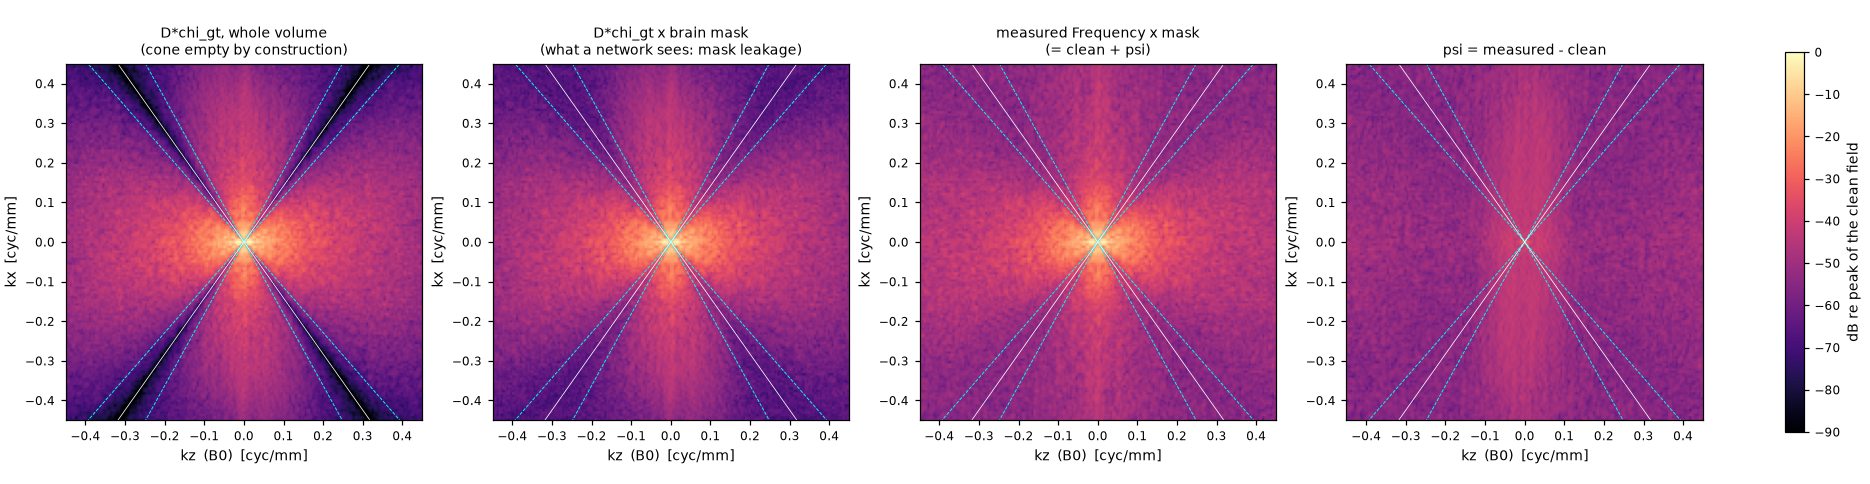

In [3]:
ref_f = power_plane(field_clean_full).max()
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), constrained_layout=True)
draw(axes[0], field_clean_full, ref_f, -90, "D*chi_gt, whole volume\n(cone empty by construction)")
draw(axes[1], field_clean_mask, ref_f, -90, "D*chi_gt x brain mask\n(what a network sees: mask leakage)")
draw(axes[2], field_dirty, ref_f, -90, "measured Frequency x mask\n(= clean + psi)")
im = draw(axes[3], field_dirty - field_clean_mask, ref_f, -90, "psi = measured - clean")
fig.colorbar(im, ax=axes, shrink=0.8, label="dB re peak of the clean field")
plt.show()

## 2. Chi: our eNDI reconstructions (streaking lives here)

For chi the cone is *not* empty in the truth (`chi_gt` has content at every frequency), but the data say nothing about it (D = 0 there), so a reconstruction cannot supply it. Reference 0 dB = peak of `chi_gt x mask`. Bottom row = reconstruction minus truth.

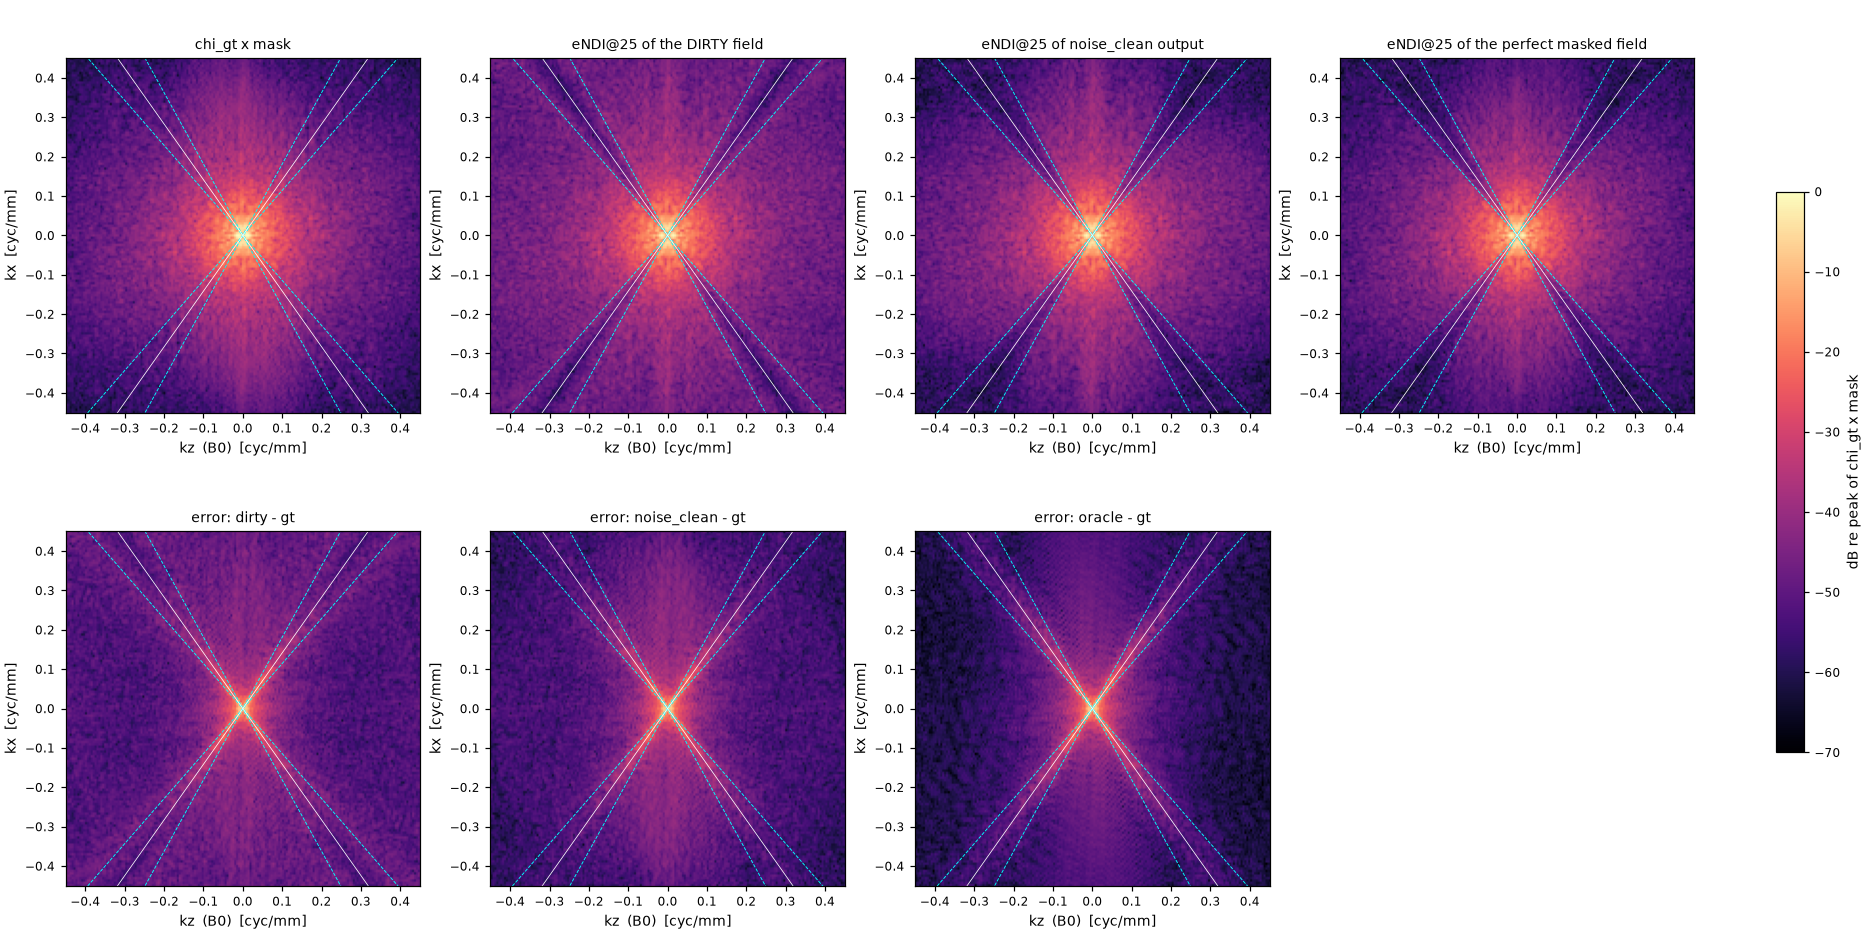

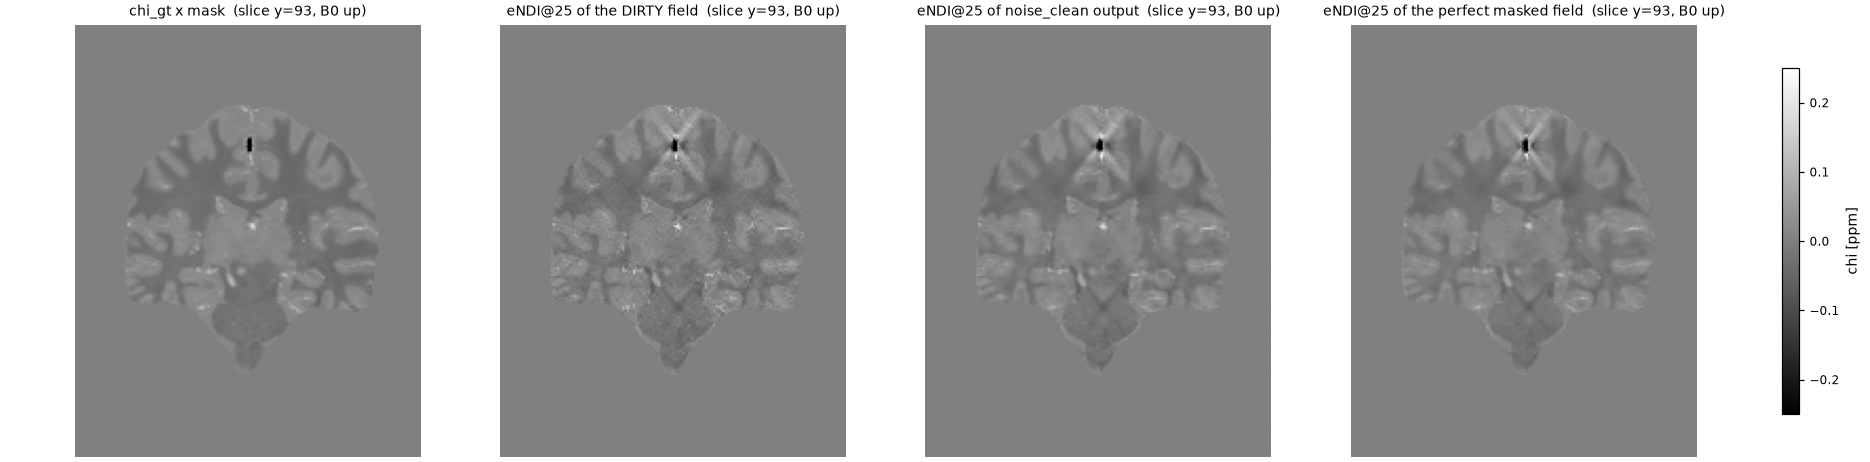

In [4]:
ref_c = power_plane(mask * chi_gt).max()
panels = [("chi_gt x mask", mask * chi_gt), ("eNDI@25 of the DIRTY field", mask * chi_hat["dirty"]),
          ("eNDI@25 of noise_clean output", mask * chi_hat["noise_clean"]), ("eNDI@25 of the perfect masked field", mask * chi_hat["oracle"])]
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6), constrained_layout=True)
for ax, (title, vol) in zip(axes[0], panels):
    draw(ax, vol, ref_c, -70, title)
errs = [("error: dirty - gt", mask * (chi_hat["dirty"] - chi_gt)), ("error: noise_clean - gt", mask * (chi_hat["noise_clean"] - chi_gt)),
        ("error: oracle - gt", mask * (chi_hat["oracle"] - chi_gt))]
for ax, (title, vol) in zip(axes[1], errs):
    im = draw(ax, vol, ref_c, -70, title)
axes[1, 3].axis("off")
fig.colorbar(im, ax=axes, shrink=0.6, label="dB re peak of chi_gt x mask")
plt.show()

# real-space view of the same reconstructions (axial through the calcification region, coronal containing B0)
cx, cy, cz = [int(v) for v in np.unravel_index(np.argmin(np.where(mask, chi_gt, 0)), chi_gt.shape)]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)
for ax, (title, vol) in zip(axes, panels):
    im = ax.imshow(vol[:, cy, :].T, cmap="gray", vmin=-0.25, vmax=0.25, origin="lower")
    ax.set_title(title + "  (slice y=%d, B0 up)" % cy); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="chi [ppm]")
plt.show()

## 3. Your question: forward-project a reconstruction, and look at the data residual

* `D*chi_hat`: because the operator multiplies by D, **any** `chi_hat` gives a field with an empty cone (up to the mask and the discrete sampling of the cone). The streaking is invisible in the forward-projected field, which is exactly why it is a null-space artifact.
* `measured - D*chi_hat`: this is the part of the data the reconstruction does not explain. Its cone content is the non-dipolar psi that eNDI could not fit (it was never allowed to put it into chi at the cone).

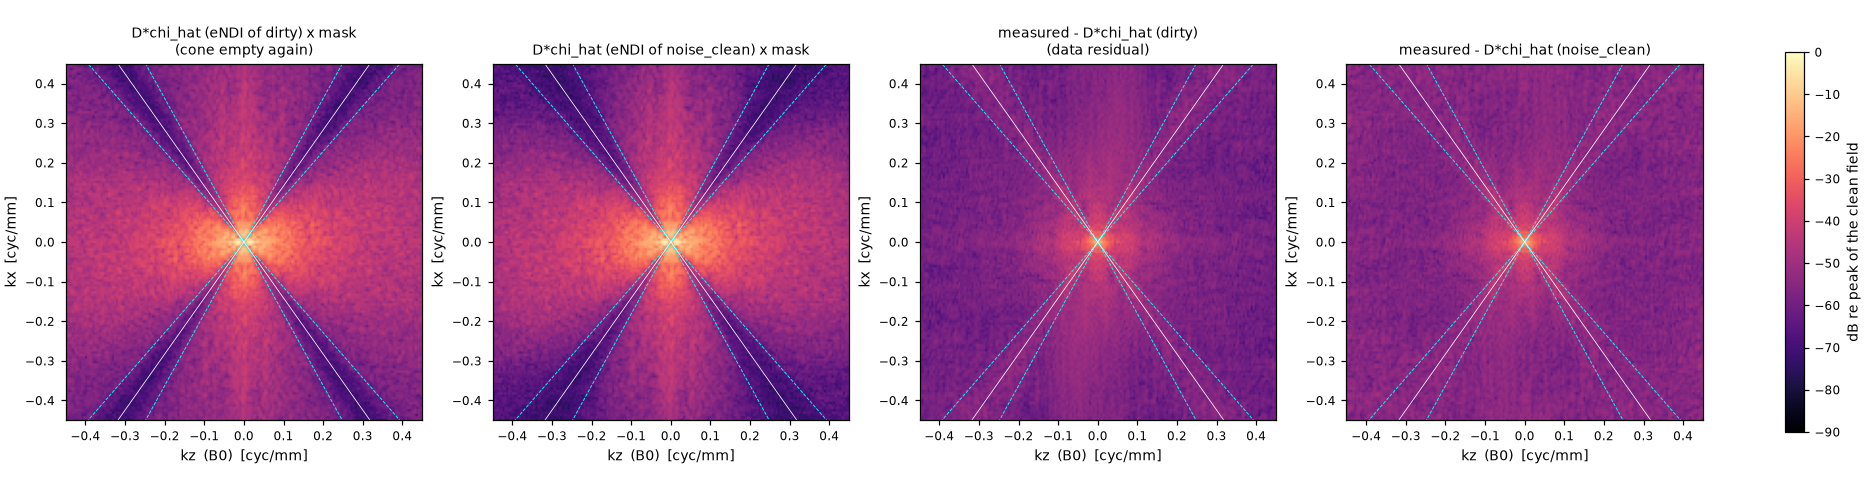

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), constrained_layout=True)
fwd_dirty = forward(mask * chi_hat["dirty"])
fwd_clean = forward(mask * chi_hat["noise_clean"])
draw(axes[0], mask * fwd_dirty, ref_f, -90, "D*chi_hat (eNDI of dirty) x mask\n(cone empty again)")
draw(axes[1], mask * fwd_clean, ref_f, -90, "D*chi_hat (eNDI of noise_clean) x mask")
draw(axes[2], mask * (field_meas - fwd_dirty), ref_f, -90, "measured - D*chi_hat (dirty)\n(data residual)")
im = draw(axes[3], mask * (field_meas - fwd_clean), ref_f, -90, "measured - D*chi_hat (noise_clean)")
fig.colorbar(im, ax=axes, shrink=0.8, label="dB re peak of the clean field")
plt.show()

## 4. Numbers: where does the energy sit in |D|?

Fraction of the (non-DC) energy in the 3D spectrum with `|D| < 0.05` and `< 0.1`. The cone band is 12% (0.05) and 24% (0.1) of the k-space *volume* for white noise (CLAUDE.md 9ap), so a value near that means 'no preference for the cone' and a value far below means 'depleted at the cone'. The curve shows the energy per k-voxel (white noise = flat) against |D|.

k-space volume with |D| < 0.05: 12.1 %, < 0.1: 24.1 %

object                              E(|D|<0.05)   E(|D|<0.1)
field: D*chi_gt (whole)                   0.06%        0.55%
field: D*chi_gt x mask                    0.58%        2.38%
field: measured x mask                    1.72%        4.49%
field: psi (measured - clean)             7.96%       16.16%
field: D*chi_hat (dirty) x mask           0.28%        1.26%
field: data residual (dirty)             16.93%       31.67%
chi: gt x mask                            6.79%       15.75%
chi: eNDI@25 dirty                        1.71%        6.90%
chi: eNDI@25 noise_clean                  1.20%        4.23%
chi: error dirty                         19.08%       39.69%
chi: error noise_clean                   23.59%       44.90%
chi: error oracle                        27.69%       51.24%


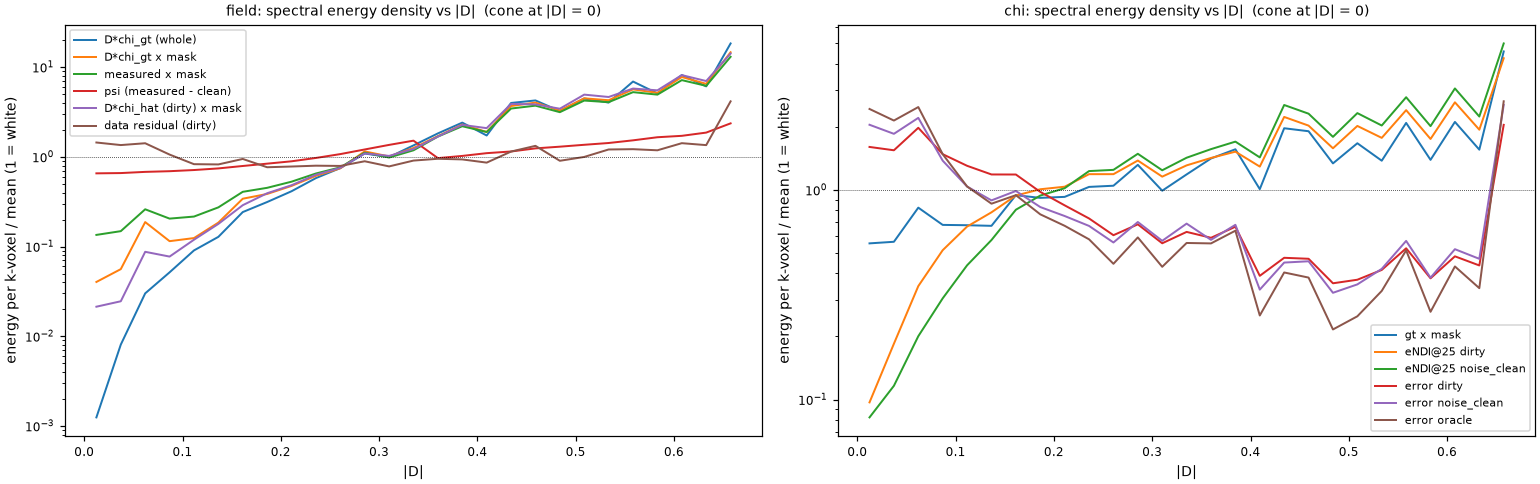

In [6]:
Dabs = np.abs(D)
nonDC = np.ones(n, bool); nonDC[0, 0, 0] = False
edges = np.linspace(0, 0.67, 28)
centers = 0.5 * (edges[:-1] + edges[1:])
which = np.digitize(Dabs[nonDC], edges) - 1

def spectrum_stats(vol):
    P = np.abs(np.fft.fftn(vol)) ** 2
    p = P[nonDC]
    tot = p.sum()
    prof = np.array([p[which == i].mean() if np.any(which == i) else np.nan for i in range(len(centers))])
    return p[Dabs[nonDC] < 0.05].sum() / tot, p[Dabs[nonDC] < 0.1].sum() / tot, prof / tot * nonDC.sum()

objs = {
    "field: D*chi_gt (whole)": field_clean_full,
    "field: D*chi_gt x mask": field_clean_mask,
    "field: measured x mask": field_dirty,
    "field: psi (measured - clean)": field_dirty - field_clean_mask,
    "field: D*chi_hat (dirty) x mask": mask * fwd_dirty,
    "field: data residual (dirty)": mask * (field_meas - fwd_dirty),
    "chi: gt x mask": mask * chi_gt,
    "chi: eNDI@25 dirty": mask * chi_hat["dirty"],
    "chi: eNDI@25 noise_clean": mask * chi_hat["noise_clean"],
    "chi: error dirty": mask * (chi_hat["dirty"] - chi_gt),
    "chi: error noise_clean": mask * (chi_hat["noise_clean"] - chi_gt),
    "chi: error oracle": mask * (chi_hat["oracle"] - chi_gt),
}
stats = {k: spectrum_stats(v) for k, v in objs.items()}
print("k-space volume with |D| < 0.05: %.1f %%, < 0.1: %.1f %%\n" % (100 * (Dabs[nonDC] < 0.05).mean(), 100 * (Dabs[nonDC] < 0.1).mean()))
print("%-34s %12s %12s" % ("object", "E(|D|<0.05)", "E(|D|<0.1)"))
for k, (a, b, _) in stats.items():
    print("%-34s %11.2f%% %11.2f%%" % (k, 100 * a, 100 * b))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), constrained_layout=True)
for ax, prefix in zip(axes, ("field", "chi")):
    for k, (_, _, prof) in stats.items():
        if k.startswith(prefix):
            ax.semilogy(centers, prof, label=k[len(prefix) + 2:], lw=1.3)
    ax.axhline(1, color="k", lw=0.5, ls=":")
    ax.set_xlabel("|D|"); ax.set_ylabel("energy per k-voxel / mean (1 = white)")
    ax.set_title(prefix + ": spectral energy density vs |D|  (cone at |D| = 0)")
    ax.legend(fontsize=7)
plt.show()

## 5. Precise accounting per |D| band: depleted, enriched, recovered

Let `X` = spectrum of `chi_gt x mask`, `Xh` = spectrum of the reconstruction x mask, `E = Xh - X` the error, and `B` a band of |D|. Per band:

* **energy share** = `sum_B |.|^2 / sum_all |.|^2` (compare with the band's share of k-space volume: that is what white noise would give);
* **recon/truth energy** = `|Xh|^2_B / |X|^2_B`: below 1 means the reconstruction has LESS energy than the truth in the band (*depleted*), above 1 MORE (*excess*);
* **recovered fraction** = `Re<Xh, X>_B / |X|^2_B`: the least-squares coefficient of the truth inside the reconstruction, 1 = fully recovered, 0 = nothing of the truth is there;
* **corr** = `Re<Xh, X>_B / (|Xh|_B |X|_B)`: how well the reconstruction's content in the band matches the truth in pattern, regardless of scale;
* **err/truth energy** = `|E|^2_B / |X|^2_B`: 1 means the error is as large as the whole truth in the band; 0 is perfect;
* **share of total error** = `|E|^2_B / sum_all |E|^2`: *enriched* means this share exceeds the band's share of k-space volume.

In [7]:
bands = [("|D|<0.05", 0.0, 0.05), ("0.05-0.15", 0.05, 0.15), ("0.15-0.30", 0.15, 0.30), (">0.30", 0.30, 9.0)]
sel = [(Dabs >= a) & (Dabs < b) for _, a, b in bands]
sel[0] = sel[0] & nonDC
Xt = np.fft.fftn(mask * chi_gt)
vol_share = [100 * s.mean() for s in sel]
truth_share = [100 * (np.abs(Xt[s]) ** 2).sum() / sum((np.abs(Xt[t]) ** 2).sum() for t in sel) for s in sel]
print("band           k-volume  truth energy")
for (nme, _, _), a, b in zip(bands, vol_share, truth_share):
    print("%-12s %7.1f%% %11.1f%%" % (nme, a, b))

recon = {"eNDI@25 dirty": chi_hat["dirty"], "eNDI@25 noise_clean": chi_hat["noise_clean"], "eNDI@25 oracle (perfect masked field)": chi_hat["oracle"]}
table = {}
for name, c in recon.items():
    Xh = np.fft.fftn(mask * c)
    Err = Xh - Xt
    etot = sum((np.abs(Err[s]) ** 2).sum() for s in sel)
    print("\n[%s]" % name)
    print("%-12s %12s %12s %8s %12s %12s" % ("band", "recon/truth", "recovered", "corr", "err/truth", "err share"))
    rows = []
    for (nme, _, _), s in zip(bands, sel):
        x, xh, e = Xt[s], Xh[s], Err[s]
        ex = (np.abs(x) ** 2).sum()
        inner = np.real(np.vdot(x, xh))
        rows.append((nme, (np.abs(xh) ** 2).sum() / ex, inner / ex, inner / np.sqrt(ex * (np.abs(xh) ** 2).sum()),
                     (np.abs(e) ** 2).sum() / ex, 100 * (np.abs(e) ** 2).sum() / etot))
        print("%-12s %12.2f %12.2f %8.2f %12.2f %11.1f%%" % rows[-1])
    table[name] = rows

print("\nexcess of err/truth over the ORACLE's (the floor of this inverter + mask), per band:")
orc = [r[4] for r in table["eNDI@25 oracle (perfect masked field)"]]
for name in ("eNDI@25 dirty", "eNDI@25 noise_clean"):
    print("  %-22s " % name + "   ".join("%s %+.2f" % (b[0], r[4] - o) for b, r, o in zip(bands, table[name], orc)))

band           k-volume  truth energy
|D|<0.05        12.1%         6.8%
0.05-0.15       23.6%        17.0%
0.15-0.30       34.9%        35.9%
>0.30           29.4%        40.3%

[eNDI@25 dirty]
band          recon/truth    recovered     corr    err/truth    err share
|D|<0.05             0.22         0.20     0.43         0.82        19.1%
0.05-0.15            0.71         0.56     0.66         0.60        35.1%
0.15-0.30            0.96         0.86     0.88         0.23        28.8%
>0.30                0.99         0.93     0.94         0.12        17.0%

[eNDI@25 noise_clean]
band          recon/truth    recovered     corr    err/truth    err share
|D|<0.05             0.13         0.18     0.49         0.78        23.6%
0.05-0.15            0.40         0.49     0.77         0.43        32.6%
0.15-0.30            0.81         0.82     0.92         0.16        26.0%
>0.30                0.93         0.91     0.95         0.10        17.9%

[eNDI@25 oracle (perfect masked field)]
b

**Real-space view of each band's error.** The error of the dirty and `noise_clean` reconstructions is split by |D| band (hard-edged filters in k-space, mask applied afterwards) and shown on the coronal slice through the calcification. If the streaks come from the band just outside the cone, they should appear in the second column.

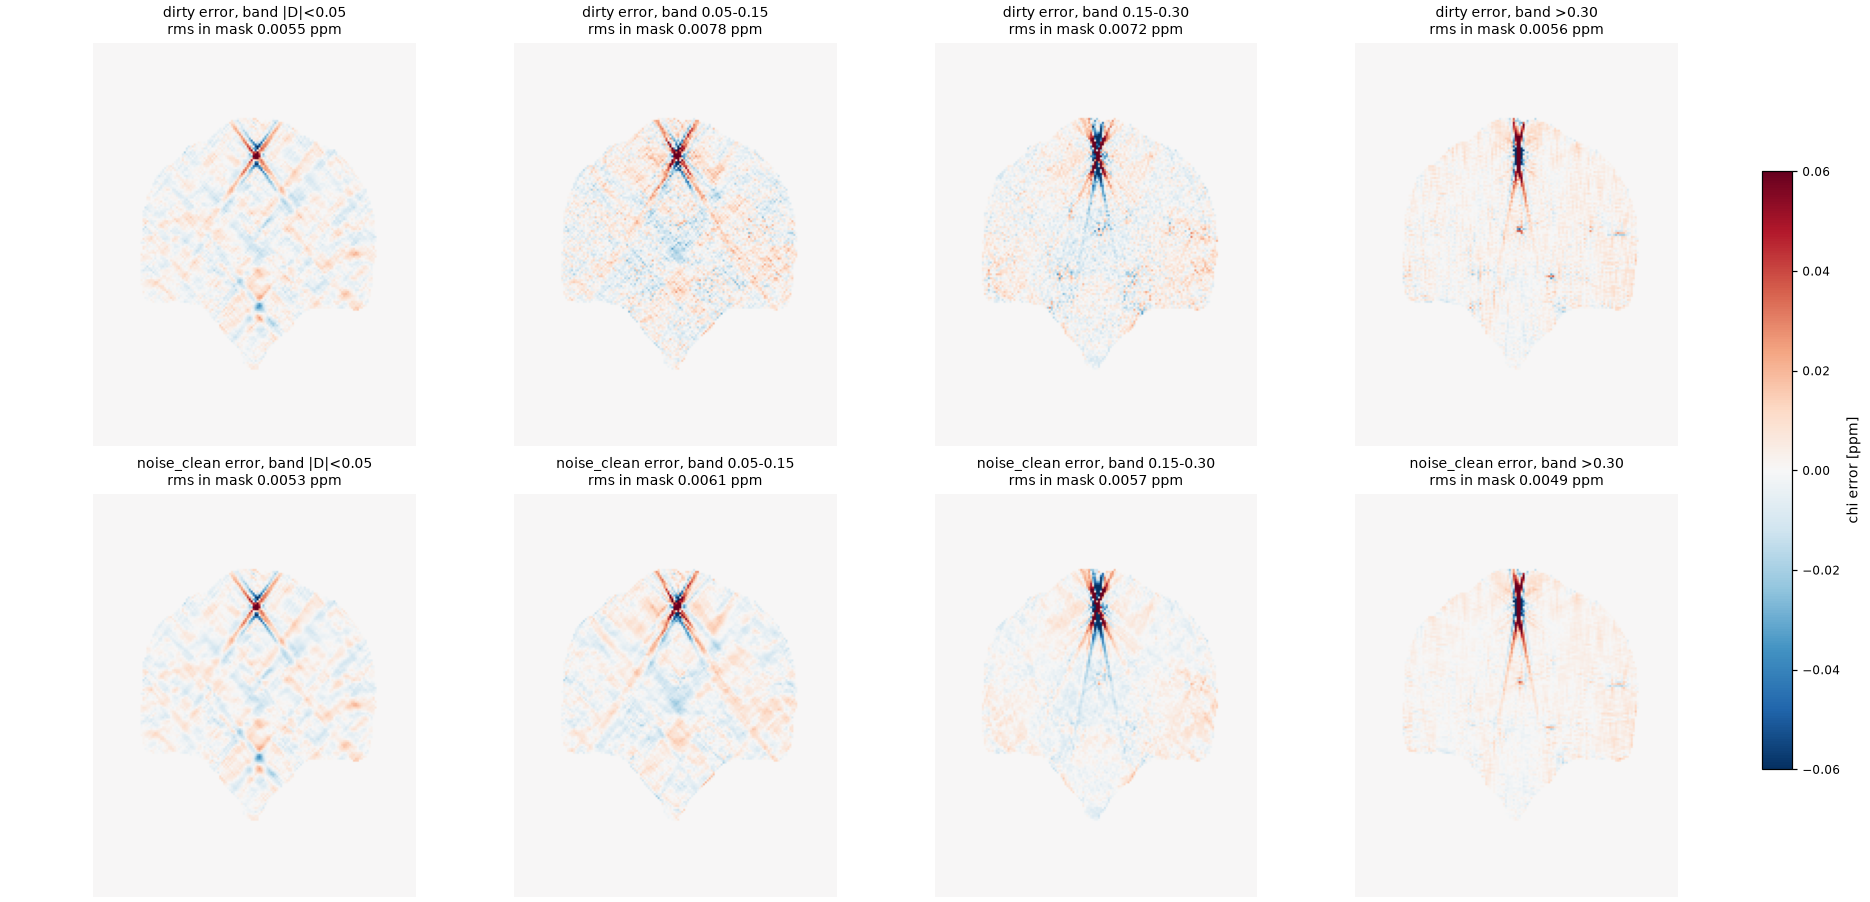

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.2), constrained_layout=True)
for row, key in enumerate(("dirty", "noise_clean")):
    Err = np.fft.fftn(mask * (chi_hat[key] - chi_gt))
    for col, ((nme, _, _), s) in enumerate(zip(bands, sel)):
        part = mask * np.real(np.fft.ifftn(np.where(s, Err, 0)))
        ax = axes[row, col]
        im = ax.imshow(part[:, cy, :].T, cmap="RdBu_r", vmin=-0.06, vmax=0.06, origin="lower")
        ax.set_title("%s error, band %s\nrms in mask %.4f ppm" % (key, nme, np.sqrt(np.mean(part[mask] ** 2))))
        ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label="chi error [ppm]")
plt.show()

## How to read it (numbers from this run; single volume, eNDI@25)

* **Clean field.** Whole-volume `D*chi_gt`: the cone is empty (0.06% of the energy in |D| < 0.05, density 1e-3 of white at |D| = 0). Seen through the brain mask it is 0.58%: mask leakage, so even a perfectly dipolar field is not exactly empty at the cone.
* **Dirty (measured) field.** 1.72% in |D| < 0.05, about 3x the masked clean field; density at the cone 0.14 of white against 0.04 for the masked clean field. The extra comes from psi, which is nearly white (7.96% in |D| < 0.05 against 12.1% for white noise): on Sim2 psi fills the cone but is not specific to it, it just stands out because the clean field is so low there. That is the Dipole-let premise for *noise-like* residuals.
* **Forward-projecting a reconstruction.** `D*chi_hat` of the eNDI@25 result has 0.28% in |D| < 0.05: empty again. The streaking cannot be seen in the field you get back (null-space property).
* **Data residual `measured - D*chi_hat`.** 16.9% in |D| < 0.05 and 31.7% in |D| < 0.1, against 12.1% and 24.1% for white noise: the part of the data eNDI cannot explain is enriched at the cone.
* **Chi reconstructions are DEPLETED at the cone, not filled.** Truth 6.8% / 15.8% in |D| < 0.05 / 0.1; eNDI@25 of the dirty field 1.7% / 6.9%, of the `noise_clean` output 1.2% / 4.2% (density at the cone 0.1 of the mean, truth 0.55). A reconstruction cannot invent cone content, and the early-stopped gradient descent barely touches it.
* **The error is ENRICHED at the cone**: its share of the total error in |D| < 0.05 is 19% (dirty), 24% (`noise_clean`), 28% (oracle = perfect masked field), against 12.1% of the k-space volume. That share rises with cleaning because the error elsewhere falls, not because the cone error grows: the band's err/truth is 0.82 / 0.78 / 0.76, i.e. almost the whole true content of the band is missing for all three (recovered fraction 0.18-0.20).
* **Section 5 refines this.** (i) In |D| < 0.05 the three reconstructions are nearly the same (err/truth 0.76-0.82; excess over the oracle only +0.06 dirty, +0.02 `noise_clean`): this band is a FLOOR of this inverter plus the mask, and its error image is the same diagonal (54.7 deg) streak pattern around the calcification for dirty, `noise_clean` and, by the numbers, the oracle. (ii) The method-dependent error is in the transition band 0.05-0.15 (excess over the oracle +0.22 dirty, +0.05 `noise_clean`; recon/truth energy 0.71 for dirty vs 0.38 oracle = commission of amplified noise) and, to a lesser degree, 0.15-0.30 (+0.11 / +0.04). (iii) Streaks are therefore not a single band: the calcification X-pattern lives in the inner bands, the diffuse texture that cleaning removes in the 0.05-0.30 bands.
* **For DPsi.** A near-cone band applied to chi mixes (i) information missing for every method (a floor), (ii) streaking from non-dipolar phase, and (iii) noise amplification, and its similarity score is symmetric, so it cannot tell omission (reconstruction has less than the truth) from commission (reconstruction has something the truth does not). It cannot be read as 'streaking' on its own. Useful checks: report each method's per-band err/truth minus the oracle's, and test every angular band against the visual streaking scores separately from the radial bands.
* Limits: one volume, one reconstruction method, early stop at 25 iterations (a longer run changes how much of the band is filled), float16 reconstructions, the figures show a `ky = 0` plane average (the table uses the full 3D spectrum), the mask is included in every spectrum.